# Chinese world: trends by the dates used
The same Chinese-world individuals placed in time three ways (birth, death, active life), each with and without **estimated** dates and with and without **coarse** dates. The curves show how much the trend depends on which dates are kept.

In [1]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from style import *

DB_PATH = '../../data/cultura/cultura_enriched_v3.2.duckdb'
POLITY_DB_PATH = '../../data/cultura/humans_clean_enriched_v3.duckdb'

FIRST_YEAR, LAST_YEAR = -500, 1900
BIN_YEARS = 50
PRECISE = ['day', 'month', 'year']
PERIOD_POLITIES = ['Northern Song', 'Ming Dynasty', 'Qing Dynasty']

ESTIMATE_COLORS = {False: NAVY, True: ORANGE}
COARSE_LINESTYLES = {False: '-', True: '--'}
FAMILY_COLORS = {'Birth': ORANGE, 'Death': GREEN, 'Active life': BLUE}
PLAIN_NUMBER = FuncFormatter(lambda x, _: f'{x:,g}')
LEGEND_FONTSIZE = 15

apply_style()

## Load data
**Chinese world**: individuals whose Wikidata citizenship (P27) is one of the 24 Cliopatria polities tagged *Chinese world*. Citizenship is used rather than the polity matching because it does not depend on any date, so the same people enter every series, including those with only coarse dates. The *Chinese world* tags are read from `humans_clean_enriched_v3`, since `cultura_enriched_v3.2` does not carry them yet.

Dates come from `cultura_enriched_v3.2`:
- **birth / death**: stated in Wikidata, or estimated from the other date and the cohort's mean age at death (`source = 'estimated'`);
- **active life**: first to last work, read from dated works or estimated from the birth and the cohort's median ages at the first and last work;
- **coarse**: a date known only to the decade, century or millennium, or an estimate built on one. Individuals with only coarse dates keep an empty year and a `coarse_label` ('16th AC'); here they are placed at the middle of their century (or millennium).

In [2]:
con = duckdb.connect(DB_PATH, read_only=True)
con.sql(f"ATTACH '{POLITY_DB_PATH}' AS polity_db (READ_ONLY)")

chinese_polities = con.sql('''
    SELECT DISTINCT name, entity.qid AS polity_qid
    FROM   polity_db.polity
    WHERE  list_contains(world, 'Chinese world') AND entity.qid IS NOT NULL
''').pl()

period_starts = con.sql('''
    SELECT   name, MIN(territory.start_year) AS start_year
    FROM     polity_db.polity, unnest(territories) AS unnested(territory)
    WHERE    list_contains($names, name)
    GROUP BY name
''', params={'names': PERIOD_POLITIES}).pl()

individuals = con.sql('''
    WITH chinese AS (
        SELECT DISTINCT entity.qid AS qid
        FROM   (SELECT entity, unnest(country_of_citizenship) AS citizenship FROM individual)
        WHERE  citizenship.entity.qid IN (SELECT polity_qid FROM chinese_polities)
    )
    SELECT entity.qid                AS qid,
           birth_date.year           AS birth_year,
           birth_date.source         AS birth_source,
           birth_date.precision      AS birth_precision,
           birth_date.coarse_label   AS birth_coarse_label,
           birth_date.field_provenance['year'].rule ILIKE '%gives only%' AS birth_from_coarse,
           death_date.year           AS death_year,
           death_date.source         AS death_source,
           death_date.precision      AS death_precision,
           death_date.coarse_label   AS death_coarse_label,
           death_date.field_provenance['year'].rule ILIKE '%gives only%' AS death_from_coarse,
           first_work_date.year      AS active_life_start,
           last_work_date.year       AS active_life_end,
           first_work_date.source    AS active_life_source,
           first_work_date.precision AS work_precision
    FROM   individual_enriched
    WHERE  entity.qid IN (SELECT qid FROM chinese)
''').pl().with_columns(pl.col('birth_from_coarse', 'death_from_coarse').fill_null(False))
con.close()

assert chinese_polities['polity_qid'].n_unique() >= 20
assert individuals['qid'].n_unique() == individuals.height
print(f'{chinese_polities.height} Chinese-world polities with a Wikidata item')
print(f'{individuals.height:,} Chinese-world individuals by citizenship')
dated = individuals.filter(pl.any_horizontal(pl.col('birth_year', 'death_year', 'birth_coarse_label', 'death_coarse_label').is_not_null()))
print(f'{dated.height:,} with a birth or a death, precise, coarse or estimated')
period_starts

24 Chinese-world polities with a Wikidata item
287,101 Chinese-world individuals by citizenship
84,679 with a birth or a death, precise, coarse or estimated


name,start_year
str,i64
"""Ming Dynasty""",1375
"""Northern Song""",961
"""Qing Dynasty""",1645


### Date sources
How each date was obtained, among the Chinese-world individuals. Almost every active life is estimated: dated works are rare.

In [3]:
def source_table(prefix):
    return (
        individuals.filter(pl.col(f'{prefix}_source').is_not_null())
        .group_by(pl.col(f'{prefix}_source').alias('source'), pl.col(f'{prefix}_precision').alias('precision'))
        .len('individuals')
        .with_columns(pl.lit(prefix).alias('date'))
        .select('date', 'source', 'precision', 'individuals')
    )


individuals = individuals.with_columns(pl.col('work_precision').alias('active_life_precision'))
date_sources = (
    pl.concat([source_table('birth'), source_table('death'), source_table('active_life')])
    .sort('date', 'individuals', descending=[False, True])
)
date_sources

date,source,precision,individuals
str,str,str,u32
"""active_life""","""estimated""","""year""",83530
"""active_life""","""dated works""","""year""",781
"""active_life""","""dated works""","""decade""",38
"""birth""","""wikidata""","""year""",54494
"""birth""","""estimated""","""year""",28320
…,…,…,…
"""death""","""wikidata""","""day""",1981
"""death""","""wikidata""","""month""",95
"""death""","""wikidata""","""century""",51


## Preprocessing
### One row per date, with its estimated and coarse flags

In [4]:
def coarse_midpoint(label):
    number = label.str.extract(r'^(\d+)').cast(pl.Int64)
    span = pl.when(label.str.contains('millennium')).then(1000).otherwise(100)
    middle = (number - 1) * span + span // 2
    return pl.when(label.str.ends_with('BC')).then(-middle).otherwise(middle)


def life_dates(prefix):
    coarse = ~pl.col(f'{prefix}_precision').is_in(PRECISE).fill_null(False) | pl.col(f'{prefix}_from_coarse')
    return (
        individuals.select(
            'qid',
            pl.coalesce(pl.col(f'{prefix}_year'), coarse_midpoint(pl.col(f'{prefix}_coarse_label'))).alias('year'),
            (pl.col(f'{prefix}_source') == 'estimated').fill_null(False).alias('estimated'),
            coarse.alias('coarse'),
        )
        .filter(pl.col('year').is_not_null())
    )


births = life_dates('birth')
deaths = life_dates('death')

birth_coarse = ~pl.col('birth_precision').is_in(PRECISE).fill_null(False) | pl.col('birth_from_coarse')
active_lives = (
    individuals.filter(pl.col('active_life_start').is_not_null() & pl.col('active_life_end').is_not_null())
    .select(
        'qid', 'active_life_start', 'active_life_end',
        (pl.col('active_life_source') == 'estimated').alias('estimated'),
        ((pl.col('work_precision') != 'year') | ((pl.col('active_life_source') == 'estimated') & birth_coarse)).alias('coarse'),
    )
)

assert pl.select(coarse_midpoint(pl.lit('16th AC'))).item() == 1550
assert pl.select(coarse_midpoint(pl.lit('2nd BC'))).item() == -150
assert pl.select(coarse_midpoint(pl.lit('2nd millennium BC'))).item() == -1500
assert (active_lives['active_life_end'] >= active_lives['active_life_start']).all()
for name, frame in [('births', births), ('deaths', deaths), ('active lives', active_lives)]:
    print(f"{name}: {frame.height:,} — estimated {frame['estimated'].sum():,}, coarse {frame['coarse'].sum():,}")
births.sample(5, seed=0)

births: 84,668 — estimated 28,320, coarse 1,166
deaths: 84,254 — estimated 22,395, coarse 104
active lives: 84,349 — estimated 83,530, coarse 747


qid,year,estimated,coarse
str,i64,bool,bool
"""Q45504130""",820,true,false
"""Q45571280""",1484,false,false
"""Q10087736""",1805,false,false
"""Q45519964""",1440,false,false
"""Q10918858""",1778,false,false


### The four variants of each series
Without estimates keeps only stated dates (Wikidata for birth and death, dated works for the active life). Without coarse dates keeps only dates precise to the year.

In [5]:
STATED = {'Birth': 'Wikidata', 'Death': 'Wikidata', 'Active life': 'Dated works'}
VARIANTS = [(False, False), (False, True), (True, False), (True, True)]


def variant_label(family, with_estimates, with_coarse):
    dates = f'{STATED[family]} + estimated' if with_estimates else f'{STATED[family]} only'
    return f"{dates}, {'with' if with_coarse else 'without'} coarse dates"


def select_variant(frame, with_estimates, with_coarse):
    keep = pl.lit(True)
    if not with_estimates:
        keep = keep & ~pl.col('estimated')
    if not with_coarse:
        keep = keep & ~pl.col('coarse')
    return frame.filter(keep)


def yearly_events(frame):
    return frame.filter(pl.col('year').is_between(FIRST_YEAR, LAST_YEAR - 1)).group_by('year').len('value')


def yearly_active(frame):
    return (
        frame.select(pl.int_ranges('active_life_start', pl.col('active_life_end') + 1).alias('year'))
        .explode('year')
        .filter(pl.col('year').is_between(FIRST_YEAR, LAST_YEAR - 1))
        .group_by('year').len('value')
    )


FAMILIES = {'Birth': (births, yearly_events), 'Death': (deaths, yearly_events), 'Active life': (active_lives, yearly_active)}

series, variant_sizes = [], []
for family, (frame, count) in FAMILIES.items():
    for with_estimates, with_coarse in VARIANTS:
        selected = select_variant(frame, with_estimates, with_coarse)
        meta = {'family': family, 'with_estimates': with_estimates, 'with_coarse': with_coarse}
        variant_sizes.append({**meta, 'variant': variant_label(family, with_estimates, with_coarse), 'individuals': selected.height})
        series.append(count(selected).with_columns(**{key: pl.lit(value) for key, value in meta.items()}))
yearly = pl.concat(series).with_columns(pl.col('value').cast(pl.Int64))
variant_sizes = pl.DataFrame(variant_sizes).with_columns(
    (100 * pl.col('individuals') / pl.col('individuals').max().over('family')).round(1).alias('% of the fullest variant')
)
assert variant_sizes.filter(pl.col('with_estimates') & pl.col('with_coarse'))['% of the fullest variant'].eq(100).all()
with pl.Config(tbl_rows=20, fmt_str_lengths=60):
    display(variant_sizes.select('family', 'variant', 'individuals', '% of the fullest variant'))

family,variant,individuals,% of the fullest variant
str,str,i64,f64
"""Birth""","""Wikidata only, without coarse dates""",55810,65.9
"""Birth""","""Wikidata only, with coarse dates""",56348,66.6
"""Birth""","""Wikidata + estimated, without coarse dates""",83502,98.6
"""Birth""","""Wikidata + estimated, with coarse dates""",84668,100.0
"""Death""","""Wikidata only, without coarse dates""",61778,73.3
"""Death""","""Wikidata only, with coarse dates""",61859,73.4
"""Death""","""Wikidata + estimated, without coarse dates""",84150,99.9
"""Death""","""Wikidata + estimated, with coarse dates""",84254,100.0
"""Active life""","""Dated works only, without coarse dates""",781,0.9


### Counts per 50-year bin
Birth and death: individuals born (or dead) in the bin. Active life: individuals active in an average year of the bin (person-years / 50).

In [6]:
binned = (
    yearly.with_columns(((pl.col('year') // BIN_YEARS) * BIN_YEARS).alias('bin'))
    .group_by('family', 'with_estimates', 'with_coarse', 'bin')
    .agg(pl.col('value').sum())
    .with_columns(
        pl.when(pl.col('family') == 'Active life').then(pl.col('value') / BIN_YEARS).otherwise(pl.col('value')).alias('value')
    )
    .sort('family', 'with_estimates', 'with_coarse', 'bin')
)
assert binned['bin'].min() >= FIRST_YEAR and binned['bin'].max() <= LAST_YEAR - BIN_YEARS
(
    binned.filter(pl.col('family') == 'Birth')
    .with_columns(pl.format('est={} coarse={}', 'with_estimates', 'with_coarse').alias('variant'))
    .pivot(on='variant', index='bin', values='value')
    .sort('bin')
    .tail(12)
)

bin,est=false coarse=false,est=false coarse=true,est=true coarse=false,est=true coarse=true
i64,f64,f64,f64,f64
1300,723.0,724.0,936.0,956.0
1350,824.0,851.0,977.0,1015.0
1400,3644.0,3645.0,3726.0,3732.0
1450,3416.0,3426.0,3532.0,3551.0
1500,4774.0,4780.0,4842.0,4851.0
…,…,…,…,…
1650,3122.0,3138.0,3695.0,3720.0
1700,3350.0,3350.0,4306.0,4313.0
1750,4787.0,4799.0,6157.0,6176.0


### Share of each series per dynastic period
Period limits are the first years of Northern Song, Ming and Qing in Cliopatria. A shift of the shares between variants is a change of trend, not only of level.

In [7]:
starts = dict(zip(period_starts['name'], period_starts['start_year']))
PERIODS = [
    ('Before Song', FIRST_YEAR, starts['Northern Song'] - 1),
    ('Song–Yuan', starts['Northern Song'], starts['Ming Dynasty'] - 1),
    ('Ming', starts['Ming Dynasty'], starts['Qing Dynasty'] - 1),
    ('Qing', starts['Qing Dynasty'], LAST_YEAR - 1),
]

period_of = pl.lit(None, dtype=pl.String)
for label, lo, hi in PERIODS:
    period_of = pl.when(pl.col('year').is_between(lo, hi)).then(pl.lit(label)).otherwise(period_of)

period_shares = (
    yearly.with_columns(period_of.alias('period'))
    .group_by('family', 'with_estimates', 'with_coarse', 'period')
    .agg(pl.col('value').sum())
    .with_columns((100 * pl.col('value') / pl.col('value').sum().over('family', 'with_estimates', 'with_coarse')).round(1).alias('share'))
    .with_columns(pl.struct('family', 'with_estimates', 'with_coarse').map_elements(
        lambda row: variant_label(row['family'], row['with_estimates'], row['with_coarse']), return_dtype=pl.String).alias('variant'))
    .pivot(on='period', index=['family', 'variant'], values='share')
    .join(variant_sizes.select('family', 'variant', pl.int_range(pl.len()).alias('order')), on=['family', 'variant'])
    .sort('order')
    .select('family', 'variant', *[label for label, _, _ in PERIODS])
)
assert period_shares.null_count().sum_horizontal().item() == 0
with pl.Config(tbl_rows=20, fmt_str_lengths=60):
    display(period_shares)

family,variant,Before Song,Song–Yuan,Ming,Qing
str,str,f64,f64,f64,f64
"""Birth""","""Wikidata only, without coarse dates""",11.4,16.0,33.7,38.9
"""Birth""","""Wikidata only, with coarse dates""",11.8,16.1,33.5,38.6
"""Birth""","""Wikidata + estimated, without coarse dates""",32.5,12.8,24.4,30.4
"""Birth""","""Wikidata + estimated, with coarse dates""",32.9,12.9,24.2,30.0
"""Death""","""Wikidata only, without coarse dates""",45.4,15.5,8.5,30.7
"""Death""","""Wikidata only, with coarse dates""",45.4,15.5,8.5,30.6
"""Death""","""Wikidata + estimated, without coarse dates""",34.1,13.4,20.1,32.4
"""Death""","""Wikidata + estimated, with coarse dates""",34.1,13.4,20.1,32.4
"""Active life""","""Dated works only, without coarse dates""",1.2,18.6,27.3,53.0


## Figures
The y axis is logarithmic, so that a series a hundred times smaller (stated dates only) still shows its shape; empty bins are skipped. Colour: with (orange) or without (blue) estimated dates. Line: with (dashed) or without (solid) coarse dates.

In [8]:
def plot_family(family, ylabel):
    fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
    for with_estimates, with_coarse in VARIANTS:
        rows = binned.filter(
            (pl.col('family') == family) & (pl.col('with_estimates') == with_estimates) & (pl.col('with_coarse') == with_coarse)
        )
        ax.plot(rows['bin'] + BIN_YEARS / 2, rows['value'], color=ESTIMATE_COLORS[with_estimates],
                linestyle=COARSE_LINESTYLES[with_coarse], marker='o', markersize=4,
                label=variant_label(family, with_estimates, with_coarse))
    ax.set_yscale('log')
    ax.set_ylim(top=binned.filter(pl.col('family') == family)['value'].max() * 30)
    ax.yaxis.set_major_formatter(PLAIN_NUMBER)
    ax.set_xlim(FIRST_YEAR, LAST_YEAR)
    ax.set_xlabel('Year')
    ax.set_ylabel(ylabel)
    ax.grid(axis='y')
    ax.legend(loc='upper left', fontsize=LEGEND_FONTSIZE)
    plt.show()

### Figure 1: Births per 50 years, Chinese world

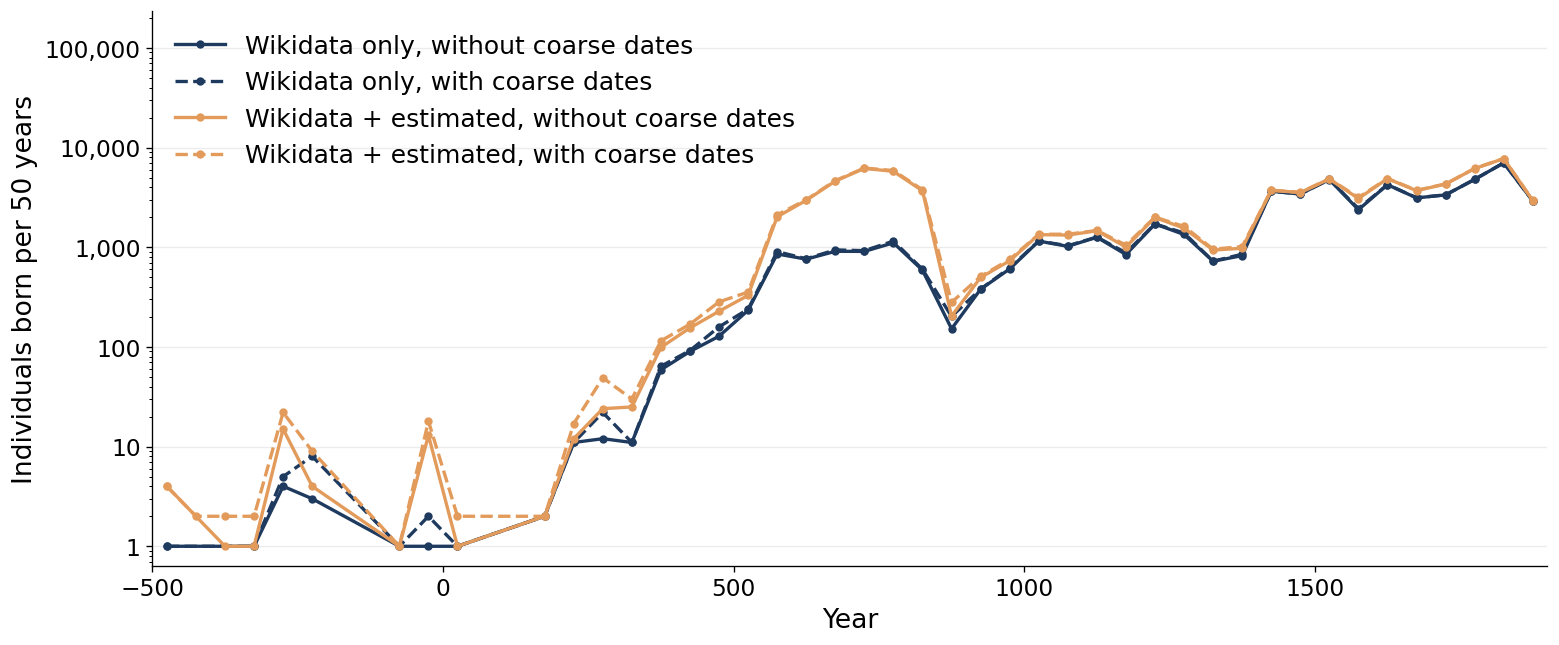

In [9]:
plot_family('Birth', 'Individuals born per 50 years')

### Figure 2: Deaths per 50 years, Chinese world

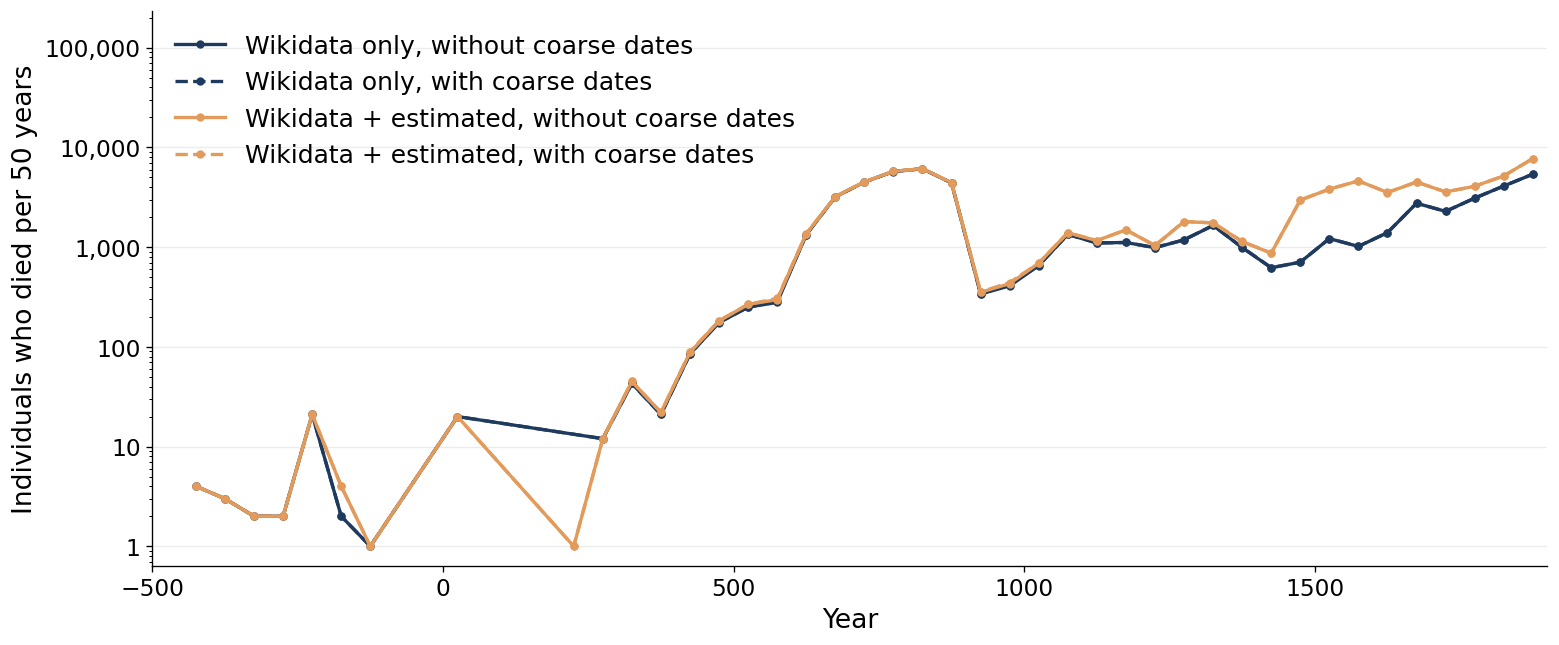

In [10]:
plot_family('Death', 'Individuals who died per 50 years')

### Figure 3: Active individuals per year, Chinese world
Without estimates, only the few individuals with dated works remain.

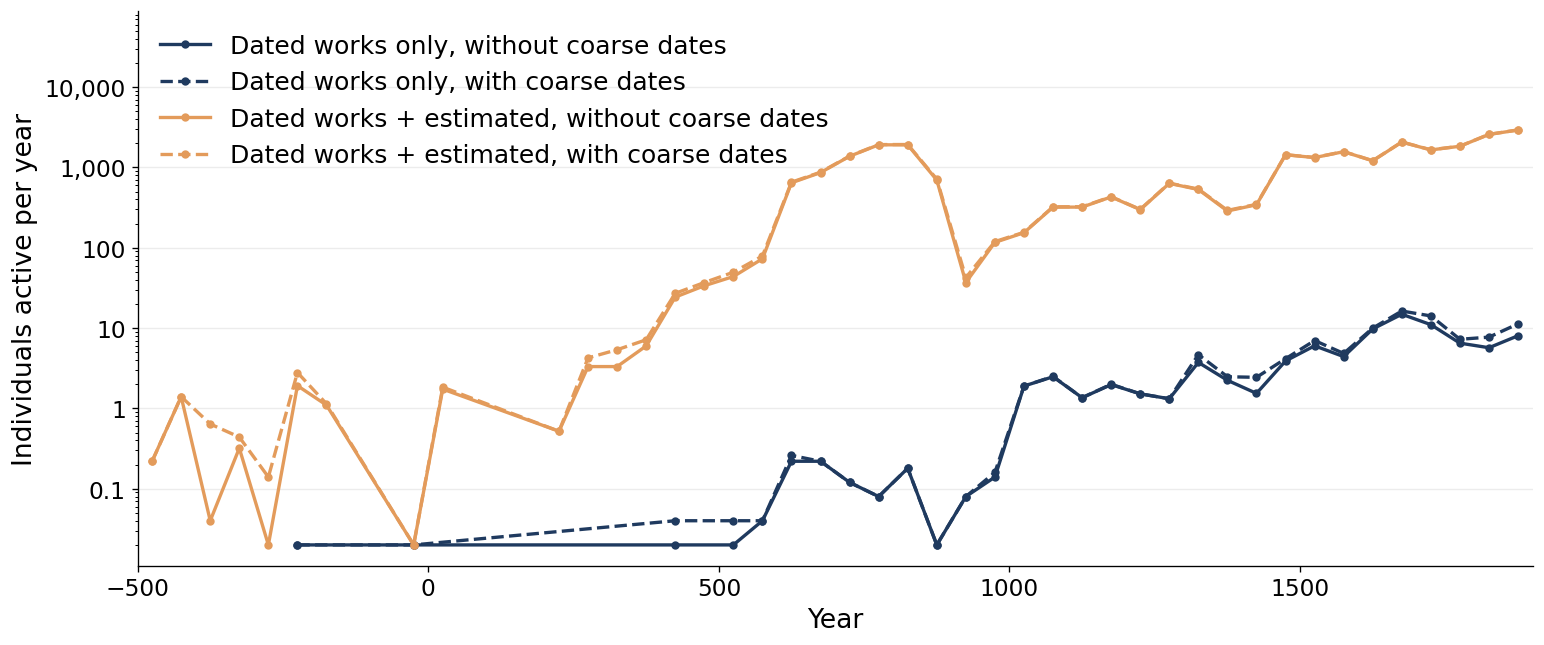

In [11]:
plot_family('Active life', 'Individuals active per year')

### Figure 4: Birth, death and active life, all dates kept
Stated, estimated and coarse dates together. Each curve is the share of its own total per 50-year bin, so that the three timings compare directly: births lead, deaths trail, and the active life sits between them.

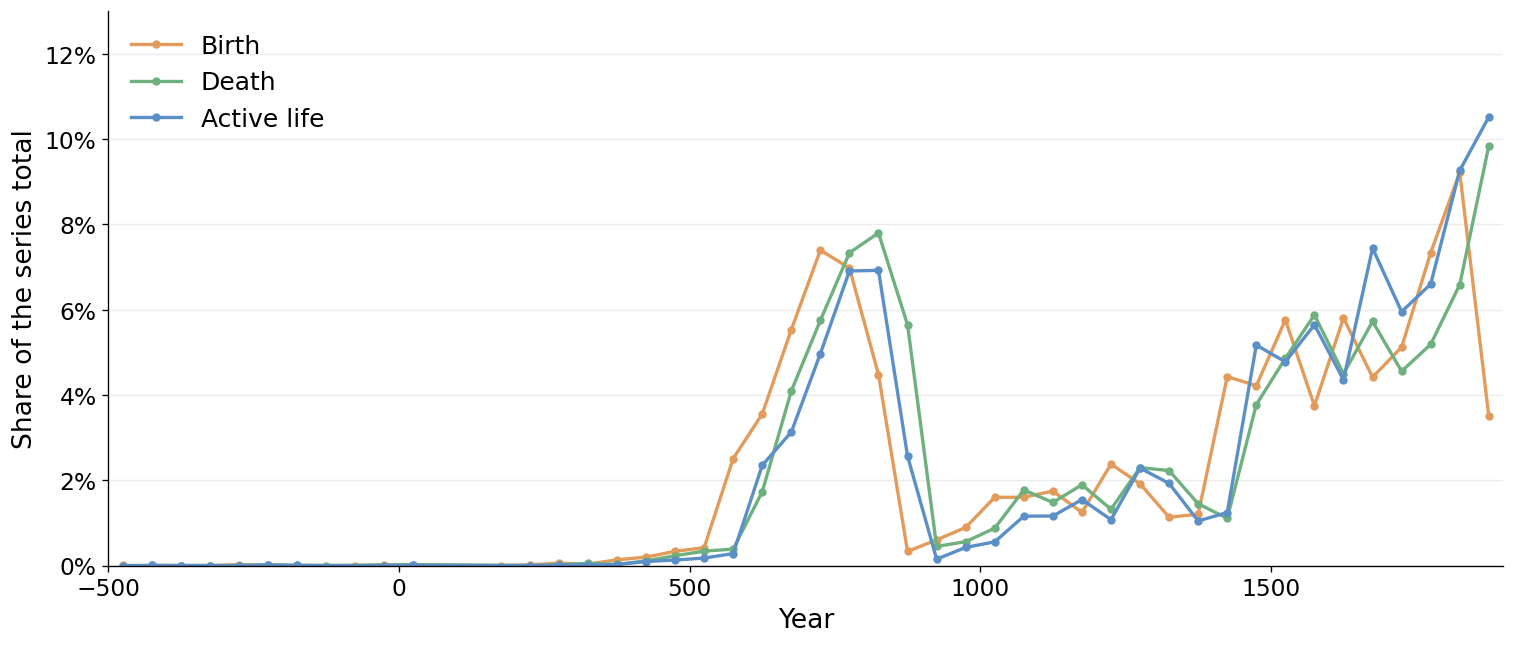

In [12]:
fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
for family, color in FAMILY_COLORS.items():
    rows = binned.filter((pl.col('family') == family) & pl.col('with_estimates') & pl.col('with_coarse'))
    ax.plot(rows['bin'] + BIN_YEARS / 2, 100 * rows['value'] / rows['value'].sum(), color=color, marker='o', markersize=4,
            label=family)
ax.set_xlim(FIRST_YEAR, LAST_YEAR)
ax.yaxis.set_major_formatter(PERCENT)
ax.set_xlabel('Year')
ax.set_ylim(0, 13)
ax.set_ylabel('Share of the series total')
ax.grid(axis='y')
ax.legend(loc='upper left', fontsize=LEGEND_FONTSIZE)
plt.show()